# Jupyter-Notebook zur Vorlesungsbegleitung k-Means


In [1]:
import matplotlib.pyplot as plt
import numpy as np

## Anlegen eines Beispielsets

Mit diesem Code erzeugen wir ein Beispieldatenset aus 2-dim Vektoren, mit 300 Samples. Die Beispieldaten lassen sich in 4 Cluster einteilen.

(300, 2)
(300,)


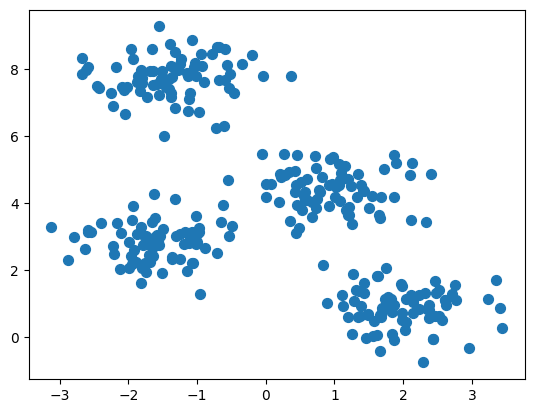

In [2]:
from sklearn.datasets import make_blobs
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)

print(X.shape) 
print(y_true.shape)
plt.scatter(X[:, 0], X[:, 1], s=50);

In [3]:

egs,egs_y = make_blobs(n_samples=324, n_features=13, centers=4, cluster_std=0.60, random_state=0)
print(egs.shape)

print(egs[0])

(324, 13)
[ 0.39750287  3.83420983  1.98903394  0.26488658 -1.03475531  3.19576046
 -1.08079832  8.03880249 10.48588135 -2.61248814  4.51363599  0.69747851
  1.3305291 ]


## k-Means aus SKLearn

Der k-Means-Algorithmus ist in SKLearn zu finden. Am Beispiel obiger erzeugter Daten betrachten wir seine Funktionsweise.

In [4]:
from sklearn.cluster import KMeans
kmeans = KMeans(n_clusters=4)
kmeans.fit(X)
y_kmeans = kmeans.predict(X)
print("type:",  type(y_kmeans)) 

type: <class 'numpy.ndarray'>


## Plotten der Cluster

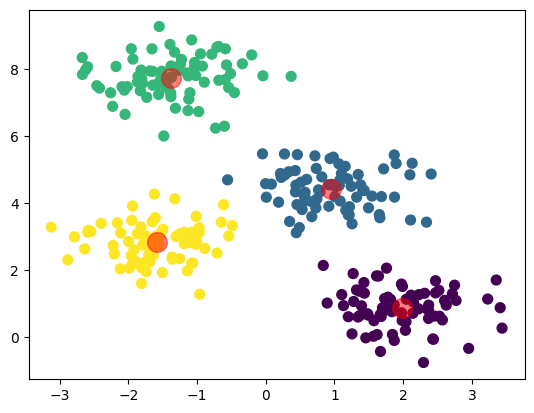

In [5]:
plt.scatter(X[:, 0], X[:, 1], c=y_kmeans, s=50, cmap='viridis')

centers = kmeans.cluster_centers_
plt.scatter(centers[:, 0], centers[:, 1], c='red', s=200, alpha=0.5)

## Initialisierung


Die Initialiserung ist ein wichtiger Schritt. Dieses Beispiel zeigt, was bei der Initalisierung schieflaufen kann.

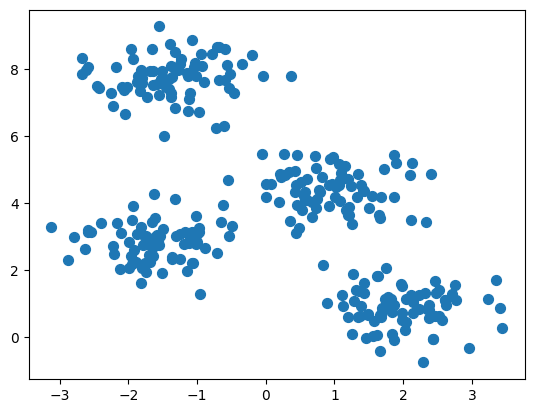

In [6]:
X, y_true = make_blobs(n_samples=300, centers=4,
                       cluster_std=0.60, random_state=0)
plt.scatter(X[:, 0], X[:, 1], s=50);

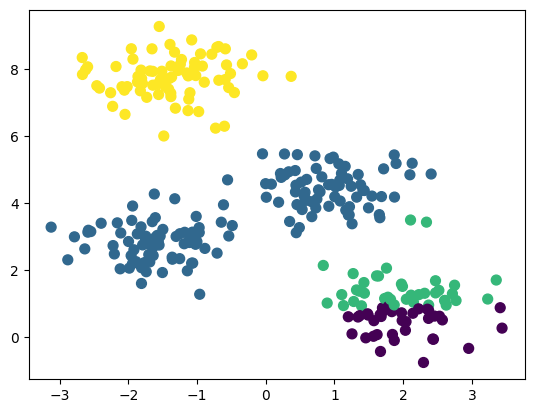

In [7]:
# n_init determines the number of iterations before choosing the best run
# n_init = 1 means it gets no chance to self-correct
kmeans = KMeans(n_clusters=4,n_init=1,init='random',random_state=4) #1 und 4

kmeans.fit(X)
y_kmeans = kmeans.predict(X)

plt.scatter(X[:, 0], X[:, 1], c=y_kmeans,
            s=50, cmap='viridis');

## Beispiele des Clustern

Wir wenden nun den kMeans auf unterschiedliche Daten an und interpretieren die Ausgabe.

### Digit-Daten

 Zuerst auf *digit*-Daten, das sind 8x8 Bilder als Beispieldatensatz in sklearn.

In [8]:
# Einlesen der digit-Daten

from sklearn.datasets import load_digits
digits = load_digits()
print(digits.data.shape)

(1797, 64)


In [9]:
#k-means mit 10 cluster
n_cluster=10
kmeans = KMeans(n_clusters=10, random_state=0)
clusters = kmeans.fit_predict(digits.data)

#### Ausgabe der Zentren, reshape als 8x8 Bild

(10, 64)


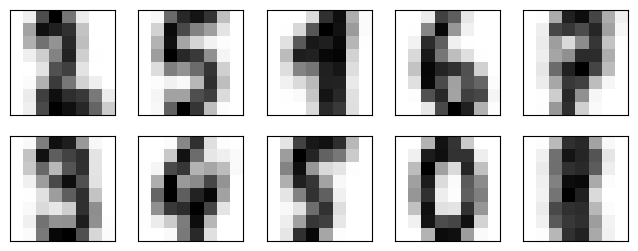

In [10]:
y=(int)(n_cluster/2)

fig, ax = plt.subplots(2, y, figsize=(8, 3))
print(kmeans.cluster_centers_.shape)

centers = kmeans.cluster_centers_.reshape(n_cluster, 8, 8)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap=plt.cm.binary)


### MNist-Fashion als naechsten Datensatz

In [11]:
from tensorflow.keras.datasets import fashion_mnist


((trainX, trainY), (testX, testY)) = fashion_mnist.load_data()
testData=testX.reshape(10000,784)

n_cluster=10
kmeans = KMeans(n_clusters=10)
clusters = kmeans.fit_predict(testData)
kmeans.cluster_centers_.shape

(10, 784)

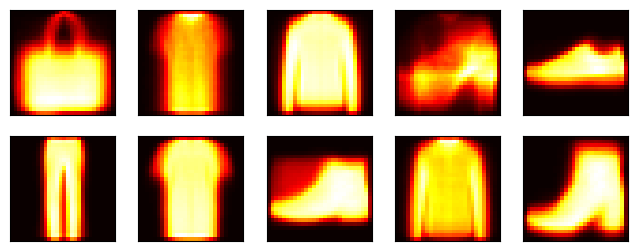

In [12]:
y=(int)(n_cluster/2)
fig, ax = plt.subplots(2, y, figsize=(8, 3))
centers = kmeans.cluster_centers_.reshape(n_cluster, 28, 28)
for axi, center in zip(ax.flat, centers):
    axi.set(xticks=[], yticks=[])
    axi.imshow(center, interpolation='nearest', cmap='hot')

## Nicht linear-trennbare Daten

### Wie verhält sich der Algorithmus auf nicht linear-trennbare Daten? 

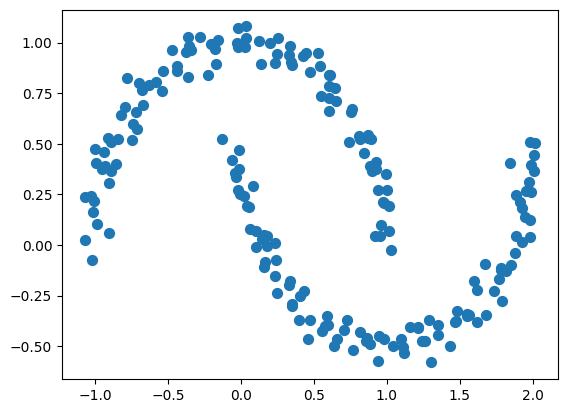

In [13]:
from sklearn.datasets import make_moons
X, y = make_moons(200, noise=.05, random_state=0)

plt.scatter(X[:, 0], X[:, 1], s=50);

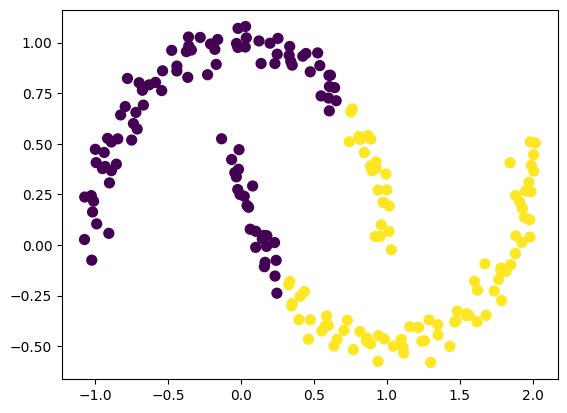

In [14]:
labels = KMeans(2, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,
            s=50, cmap='viridis');

### Lösung:  Mehrere Cluster

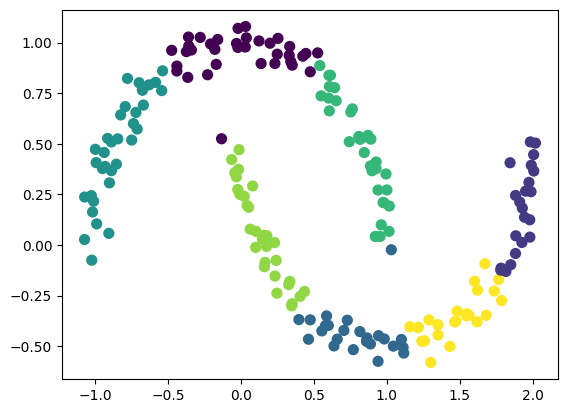

In [15]:
labels = KMeans(7, random_state=0).fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,
            s=50, cmap='viridis');

### Transformation in einen anderen Raum

In [16]:
def trans(x):
    return(np.power(x,6))

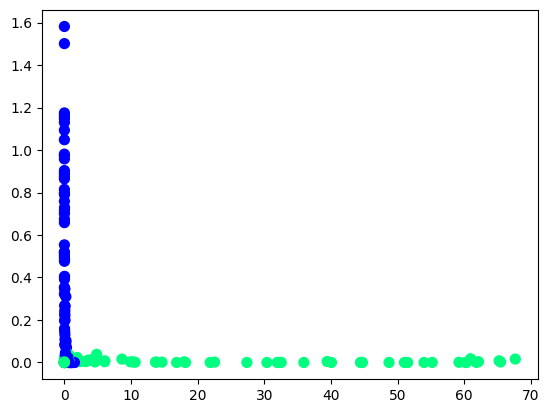

In [17]:
X_squared = trans(X)

plt.scatter(X_squared[:, 0], X_squared[:, 1], c=y, s=50, cmap='winter')


### Anwenden von Kernels?

C:\Users\Yousef\dev_glob\ml2026\bocklet\Lib\site-packages\sklearn\manifold\_spectral_embedding.py:324: UserWarning: Graph is not fully connected, spectral embedding may not work as expected.
  warnings.warn(


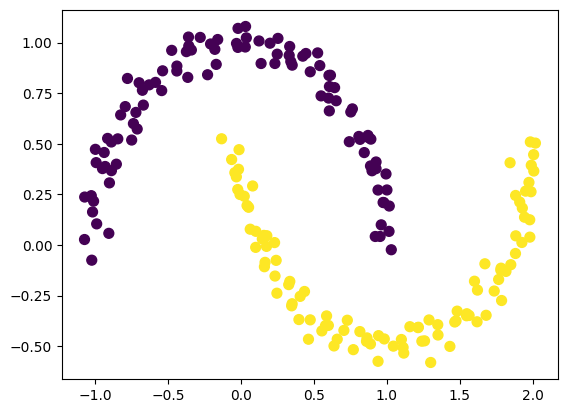

In [18]:
from sklearn.cluster import SpectralClustering
model = SpectralClustering(n_clusters=2, affinity='nearest_neighbors',
                           assign_labels='kmeans')
labels = model.fit_predict(X)
plt.scatter(X[:, 0], X[:, 1], c=labels,
            s=50, cmap='viridis');